# 2. Validation case study: Sailor et al. (2026) traverses

This notebook compares `dc_plume` with the only published air-temperature measurements downwind of operating data centers:

> Sailor, D.J., Samareh Abolhassani, S., Martin, E.P. (2026). Data center waste heat as an emerging urban thermal hazard: first field measurements of neighborhood-scale air temperature impacts. *ASME Journal of Engineering for Sustainable Buildings and Cities* 7(2), 024501. https://doi.org/10.1115/1.4071922 (open access, CC-BY 4.0)

Sailor et al. drove vehicles with aspirated temperature sensors (1.6–2.2 m) upwind and downwind of Phoenix-area data centers and reported the mean downwind-minus-upwind air temperature. The per-traverse values from their Section 3 and Table 1 are in `validation/benchmarks/sailor2026_cases.csv`, with the source of every number. Please cite the paper when you use them.

The comparison follows standard dispersion-model evaluation (Chang & Hanna 2004): run the model for each observed case and compute FAC2, fractional bias (FB), NMSE and geometric mean bias (MG).

In [1]:
import os, sys
# run this notebook from the tutorial/ folder or the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "tutorial" else os.getcwd()
sys.path.insert(0, ROOT)
import numpy as np
import matplotlib.pyplot as plt
import dc_plume as dp
print("dc_plume", "loaded")

dc_plume loaded


In [2]:
import pandas as pd
cases = pd.read_csv(os.path.join(ROOT, "validation", "benchmarks", "sailor2026_cases.csv"))
cases[["case", "site", "date_time_local", "IT_MW", "T_C", "U_ms", "stability", "dist_min_m", "dist_max_m", "obs_dT_mean_C"]]

,case,site,date_time_local,IT_MW,T_C,U_ms,stability,dist_min_m,dist_max_m,obs_dT_mean_C
0,a,"CyrusOne PHX1-PHX8, Chandler AZ",2025-06-18 14:25-14:45,169,42.7,2.1,B,100,500,0.8
1,b,"CyrusOne PHX1-PHX8, Chandler AZ",2025-08-08 11:05-11:10,169,39.1,1.5,A,100,400,0.5
2,d,"Digital Realty, 2121 S Price Rd, Chandler AZ",2025-10-25 10:55-11:05,34,24.2,2.1,B,100,400,1.0
3,e,"NTT PH1, 10256 Elliot Rd, Mesa AZ",2025-10-25 10:30-10:40,36,25.0,1.5,A,200,300,0.9


## Model set-up for one case

Inputs not in the paper are set to typical values and varied afterwards:
- heat rejected = 1.3 × IT × load fraction (PUE 1.3, as in the paper; load fraction 0.5–1.0, central 0.75);
- dry-cooler exhaust 11 K above ambient (reported 8–14 K) at 3 m/s;
- fan array with 80 kW per fan (50–150 kW);
- stability from the Turner method for the date and time; daytime mixing height 1,500–3,000 m.

ΔT is averaged over the downwind distances of the published averaging area.

In [3]:
import warnings

def predict(c, load=0.75, fan_heat=80e3):
    Q = 1.3 * c.IT_MW * load * 1e6
    L = float(np.sqrt(c.footprint_m2))                      # square equivalent of the heat-rejection area
    amb = dp.Ambient(T=c.T_C, RH=0.15, U10=c.U_ms, stability=c.stability,
                     mixing_height=c.zi_m, elevation=370.0)
    src = dp.dry_cooler_source(Q, 11.0, amb, height=c.height_m, footprint_x=L, footprint_y=L,
                               building_height=c.height_m - 2.0, exit_velocity=3.0, fan_heat=fan_heat)
    x = L / 2 + np.linspace(c.dist_min_m, c.dist_max_m, 9)   # distances beyond the downwind edge
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return float(np.mean(dp.plume(src, amb, x)["dT"]))

c = cases.iloc[3]
print(c.site, "| observed", c.obs_dT_mean_C, "C | predicted", round(predict(c), 2), "K")

NTT PH1, 10256 Elliot Rd, Mesa AZ | observed 0.9 C | predicted 0.9 K


## All cases, with uncertainty ranges and the merged-plume comparison

In [4]:
rows = []
for c in cases.itertuples():
    rng = [predict(c, l, f) for l in (0.5, 1.0) for f in (50e3, 150e3)]
    rows.append(dict(case=c.case, observed=c.obs_dT_mean_C, predicted=predict(c),
                     lo=min(rng), hi=max(rng), merged_plume=predict(c, fan_heat=None)))
res = pd.DataFrame(rows).round(3)
res

,case,observed,predicted,lo,hi,merged_plume
0,a,0.8,0.555,0.279,0.927,0.006
1,b,0.5,0.913,0.503,1.327,0.002
2,d,1.0,0.398,0.278,0.566,0.009
3,e,0.9,0.896,0.537,1.265,0.003


## Performance statistics (Chang & Hanna 2004)

In [5]:
def metrics(o, p):
    o, p = np.asarray(o, float), np.asarray(p, float)
    return dict(FAC2=np.mean((p / o >= 0.5) & (p / o <= 2)),
                FB=(o.mean() - p.mean()) / (0.5 * (o.mean() + p.mean())),
                NMSE=np.mean((o - p) ** 2) / (o.mean() * p.mean()),
                MG=np.exp(np.mean(np.log(o / p))))

print("fan array       :", {k: round(v, 2) for k, v in metrics(res.observed, res.predicted).items()})
print("one merged plume:", {k: round(v, 2) for k, v in metrics(res.observed, res.merged_plume).items()})
print("acceptance (Chang & Hanna 2004): FAC2 >= 0.5, |FB| <= 0.3, NMSE <= 1.5, 0.7 <= MG <= 1.3")

fan array       : {'FAC2': 0.75, 'FB': 0.15, 'NMSE': 0.27, 'MG': 1.19}
one merged plume: {'FAC2': 0.0, 'FB': 1.98, 'NMSE': 166.57, 'MG': 182.57}
acceptance (Chang & Hanna 2004): FAC2 >= 0.5, |FB| <= 0.3, NMSE <= 1.5, 0.7 <= MG <= 1.3


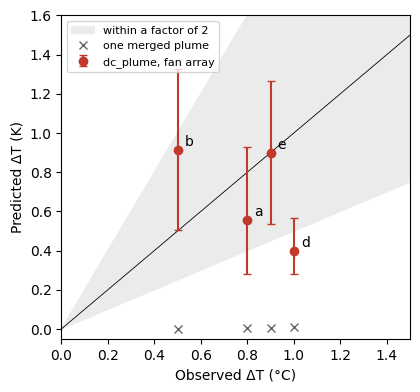

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 4.2))
ax.fill_between([0, 3], [0, 1.5], [0, 6], color="0.92", label="within a factor of 2")
ax.plot([0, 3], [0, 3], "k-", lw=.6)
ax.errorbar(res.observed, res.predicted, yerr=[res.predicted - res.lo, res.hi - res.predicted],
            fmt="o", color="#c0392b", capsize=3, label="dc_plume, fan array")
ax.plot(res.observed, res.merged_plume, "x", color="0.4", label="one merged plume")
for r in res.itertuples():
    ax.annotate(r.case, (r.observed, r.predicted), xytext=(5, 3), textcoords="offset points")
ax.set(xlim=(0, 1.5), ylim=(-0.05, 1.6), xlabel="Observed ΔT (°C)", ylabel="Predicted ΔT (K)")
ax.legend(fontsize=8, loc="upper left")

## Adding your own case

Add a row to `sailor2026_cases.csv`, or build a similar CSV for new measurements, with the facility's IT load, heat-rejection area, height, the observed upwind/downwind difference, the distances of the downwind averaging area, and the weather during the measurement. Then rerun this notebook or

```bash
python validation/benchmarks/benchmark_sailor2026.py
```

**Limits of this benchmark.** It has four daytime cases at 100–500 m. It tests the near-field daytime magnitude, not the night-time mixed layer or the decay beyond 0.5 km, and the fan-array treatment was introduced after the merged-plume version failed these cases, so it is a consistency check rather than a blind test.